# Live demo: early-exit CNN vs. full CNN on SoccerTrack

Both models share the same temporal 1D-CNN trunk (embed + 4 conv blocks, 64 channels) and read the same input: a 0.5 s window of
player positions (12 frames x 23 slots x (x, y) + a presence mask). They differ in **how many times they are allowed to answer**:

| model | heads | what it does per window |
|---|---|---|
| **full CNN** (`outputs/cnn_full`) | 1, after block 4 | always runs the whole trunk |
| **early-exit CNN** (`outputs/earlyexit`) | 4, after blocks 1-4 | runs block by block, stops at the first head whose max-softmax ≥ its threshold |

Everything below runs the committed checkpoints on real windows from match 117093, second half. Nothing is re-trained or re-tuned.

**How to drive the demo:** run all cells once (Kernel → Restart & Run All), then play with the `WINDOW` slider in section 3, the live
clip in section 4, the threshold slider in section 6 and the battery slider in section 7.

In [1]:
import sys, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
if not (REPO / "core").exists():            # notebook lives in notebooks/, package root is one up
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

from core import load_config, load_split, load_flops, load_thresholds, compute_metrics, stack_exit_logits
from core.flops import profile
from core.policy import apply_threshold_policy, exit_histogram, mean_flops, budget_thresholds
from models.cnn import featurize
from models.registry import load_checkpoint
from scripts.demo_runtime import stream_window        # the truly incremental early-exit loop

torch.set_num_threads(1)                             # edge scenario: one window at a time, one core
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C_FULL, C_EE, C_PRUNED, C_ACT = "#2f8f5b", "#e3a92f", "#7fb3e6", "#d65c4c"

cfg = load_config(REPO / "configs/default.yaml")
FPS, T = cfg.data.fps, round(cfg.data.fps * cfg.data.window_seconds)
print(f"repo: {REPO}\nwindow = {cfg.data.window_seconds} s = {T} frames @ {FPS} fps, {cfg.data.max_people} people slots")

repo: /Users/hiddemakimei/Desktop/git/uva/BDE/ass_3/Sports_Action_BDE_group_21
window = 0.5 s = 12 frames @ 25 fps, 23 people slots


## 1. Load the models and the data

In [2]:
full,   full_info   = load_checkpoint(REPO / "outputs/cnn_full/model.pt")
ee,     ee_info     = load_checkpoint(REPO / "outputs/earlyexit/model.pt")
pruned, pruned_info = load_checkpoint(REPO / "outputs/cnn_pruned/model.pt")   # the Pareto winner, shown for reference

flops_full   = load_flops(REPO / "outputs/cnn_full/flops.json")
flops_ee     = load_flops(REPO / "outputs/earlyexit/flops.json")
flops_pruned = load_flops(REPO / "outputs/cnn_pruned/flops.json")
FLOPS_EXIT   = [int(f) for f in flops_ee["flops_per_exit"]]          # cumulative cost to answer at exit 1..4
FLOPS_FULL   = int(flops_full["flops_per_exit"][0])

thr_by_budget = load_thresholds(REPO / "outputs/earlyexit/thresholds.json")
THRESHOLDS    = budget_thresholds(thr_by_budget, "100")               # the tuned policy used in M5/M7

pd.DataFrame({
    "model":          ["full CNN", "early-exit CNN", "pruned CNN"],
    "variant":        [full_info["variant"], ee_info["variant"], pruned_info["variant"]],
    "exits after":    [full.exit_after, ee.exit_after, pruned.exit_after],
    "trunk widths":   [full.channel_widths(), ee.channel_widths(), pruned.channel_widths()],
    "params":         [flops_full["params"], flops_ee["params"], flops_pruned["params"]],
    "size (MB)":      [flops_full["size_mb"], flops_ee["size_mb"], flops_pruned["size_mb"]],
    "FLOPs per exit": [flops_full["flops_per_exit"], FLOPS_EXIT, flops_pruned["flops_per_exit"]],
}).set_index("model")

,variant,exits after,trunk widths,params,size (MB),FLOPs per exit
model,,,,,,
full CNN,fp32,[4],"[64, 64, 64, 64, 64]",54530,0.230467,[1285888]
early-exit CNN,fp32+kd,"[1, 2, 3, 4]","[64, 64, 64, 64, 64]",54920,0.233905,"[401152, 696320, 991488, 1286656]"
pruned CNN,fp32,[4],"[32, 32, 32, 32, 32]",14978,0.071235,[348032]


The committed checkpoints expect 12-frame windows. The only local split in that exact format is the demo half
(`data/processed/demo_117093_half2.pt`, match 117093 second half), so the whole demo runs on it. Match 117093 belongs to the
**validation** split: the models were never trained on it, but the early-exit thresholds were tuned on it. The unbiased
numbers are the test-set results in the last section.

In [3]:
split = load_split(REPO / "data/processed/demo_117093_half2.pt")
X, MASK, Y = split["X"], split["mask"], split["y"]
START_FRAME = split["meta"]["start_frame"]
N = len(Y)
print(f"{N:,} windows of {X.shape[1]} frames x {X.shape[2]} slots; {100 * Y.float().mean():.1f}% contain an action "
      f"({int(Y.sum()):,} windows); covers {N * T / FPS / 60:.1f} minutes of play")

5,872 windows of 12 frames x 23 slots; 18.8% contain an action (1,102 windows); covers 47.0 minutes of play


## 2. What one window looks like

Each window is half a second of tracked positions for everyone on the pitch (normalised pitch coordinates, 0-1).
The label is 1 if a ball action (pass, shot, tackle, ...) happens inside the window.

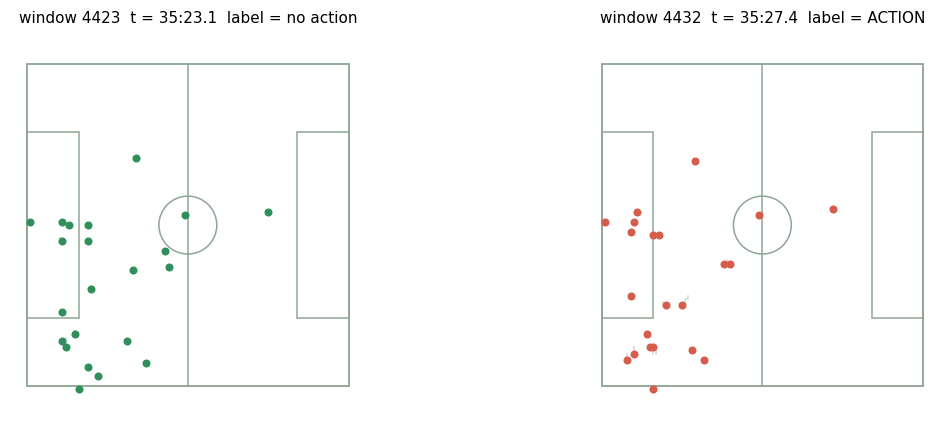

In [4]:
def draw_pitch(ax):
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, lw=1.2, color="#8fa596"))
    ax.plot([0.5, 0.5], [0, 1], color="#8fa596", lw=1)
    ax.add_patch(plt.Circle((0.5, 0.5), 0.09, fill=False, color="#8fa596", lw=1))
    for x0 in (0, 1 - 0.16):
        ax.add_patch(plt.Rectangle((x0, 0.21), 0.16, 0.58, fill=False, color="#8fa596", lw=1))
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(1.1, -0.1); ax.set_aspect("equal"); ax.axis("off")

def plot_window(i, ax=None, title=True):
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    draw_pitch(ax)
    x, m = X[i].numpy(), MASK[i].numpy().astype(bool)
    for p in range(x.shape[1]):
        pts = x[m[:, p], p]
        if len(pts) == 0:
            continue
        ax.plot(pts[:, 0], pts[:, 1], color="#c3d1c7", lw=1, alpha=0.8)
        ax.scatter(pts[-1, 0], pts[-1, 1], s=18, color=C_ACT if int(Y[i]) else C_FULL, zorder=3)
    if title:
        t = int(START_FRAME[i]) / FPS
        ax.set_title(f"window {i}  t = {t // 60:.0f}:{t % 60:04.1f}  label = {'ACTION' if int(Y[i]) else 'no action'}", fontsize=10)
    return ax

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_window(4423, axes[0]); plot_window(4432, axes[1])
plt.tight_layout(); plt.show()

## 3. One window, both models, live

`run_full` always executes the complete trunk. `stream_window` (from `scripts/demo_runtime.py`) executes the trunk block
by block and **returns as soon as a head is confident enough**, so later blocks are never computed. The FLOPs reported are
what a deployed device would actually spend.

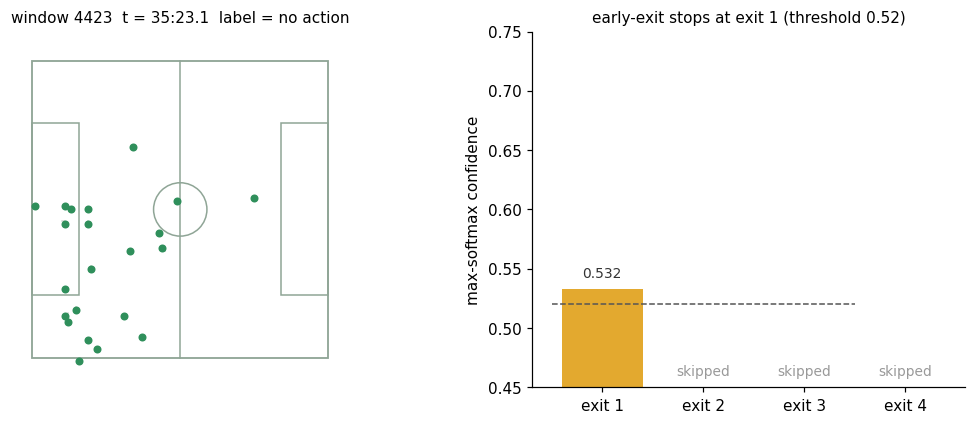

,full CNN,early-exit CNN
prediction,no action,no action
P(action),0.477,0.468
exit taken,4 (always),1
FLOPs,"1,285,888","401,152"
of full model,100%,31%
latency (ms),0.35,0.17


In [5]:
REPEATS = 10                                         # latency = median of this many runs (single calls are noisy)

@torch.no_grad()
def run_full(model, i):
    times = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        logits = model(X[i:i+1], MASK[i:i+1])[-1]
        times.append((time.perf_counter() - t0) * 1e3)
    probs = logits.softmax(-1)[0]
    return {"pred": int(probs.argmax()), "p_action": float(probs[1]), "conf": float(probs.max()), "ms": float(np.median(times))}

@torch.no_grad()
def run_both(i, thresholds=THRESHOLDS):
    f = run_full(full, i)
    runs = [stream_window(ee, X[i:i+1], MASK[i:i+1], thresholds) for _ in range(REPEATS)]
    e = runs[-1] | {"ms": float(np.median([r["ms"] for r in runs]))}
    return {
        "window": i, "label": int(Y[i]),
        "full_pred": f["pred"], "full_p_action": f["p_action"], "full_flops": FLOPS_FULL, "full_ms": f["ms"],
        "ee_pred": e["pred"], "ee_p_action": e["p_action"], "ee_exit": e["exit"] + 1,
        "ee_flops": FLOPS_EXIT[e["exit"]], "ee_ms": e["ms"], "ee_confidences": e["confidences"],
    }

for _ in range(5):                                   # warm-up so timings are not dominated by the first call
    run_both(0)

def show_window(i, thresholds=THRESHOLDS):
    r = run_both(i, thresholds)
    lab = lambda c: "ACTION" if c == 1 else "no action"
    rows = pd.DataFrame({
        "full CNN":       [lab(r["full_pred"]), f"{r['full_p_action']:.3f}", "4 (always)", f"{r['full_flops']:,}", "100%", f"{r['full_ms']:.2f}"],
        "early-exit CNN": [lab(r["ee_pred"]),   f"{r['ee_p_action']:.3f}",   r["ee_exit"],  f"{r['ee_flops']:,}",   f"{100 * r['ee_flops'] / FLOPS_FULL:.0f}%", f"{r['ee_ms']:.2f}"],
    }, index=["prediction", "P(action)", "exit taken", "FLOPs", "of full model", "latency (ms)"])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]}); fig.subplots_adjust(wspace=0.25)
    plot_window(i, axes[0])
    confs = r["ee_confidences"]
    xs = np.arange(1, 5)
    vals = [c if c is not None else 0 for c in confs]
    cols = [C_EE if c is not None else "#e6e6e6" for c in confs]
    axes[1].bar(xs, vals, color=cols, edgecolor="none")
    axes[1].plot([0.5, 3.5], [thresholds[0]] * 2, "--", color="#555", lw=1)
    for k, (c, v) in enumerate(zip(confs, vals), start=1):
        axes[1].text(k, (v if c is not None else 0.45) + 0.01, f"{c:.3f}" if c is not None else "skipped", ha="center", fontsize=9, color="#333" if c is not None else "#999")
    axes[1].set_xticks(xs, [f"exit {k}" for k in xs]); axes[1].set_ylim(0.45, 0.75)
    axes[1].set_ylabel("max-softmax confidence"); axes[1].set_title(f"early-exit stops at exit {r['ee_exit']} (threshold {thresholds[0]})", fontsize=10)
    plt.show()
    return rows

show_window(4423)

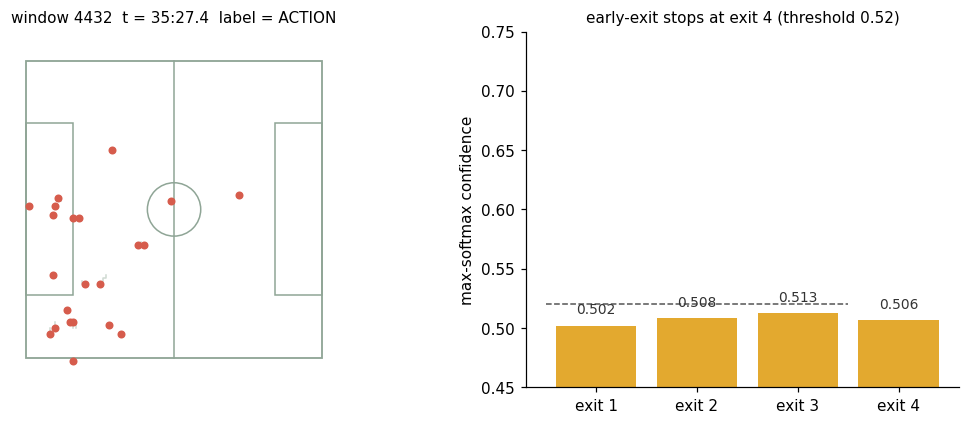

,full CNN,early-exit CNN
prediction,no action,no action
P(action),0.485,0.494
exit taken,4 (always),4
FLOPs,"1,285,888","1,286,656"
of full model,100%,100%
latency (ms),0.37,0.45


In [6]:
# A window where the early-exit model stays unsure and runs to the end
show_window(4432)

In [7]:
# Interactive: scrub through the match. Windows 4423-4442 also have the camera footage (section 7).
try:
    from ipywidgets import interact, IntSlider
    interact(lambda WINDOW: show_window(WINDOW), WINDOW=IntSlider(min=0, max=N - 1, step=1, value=4428, continuous_update=False));
except ImportError:
    print("ipywidgets not installed: call show_window(i) by hand")

interactive(children=(IntSlider(value=4428, continuous_update=False, description='WINDOW', max=5871), Output()…

## 4. Live: 10 seconds of the match with both models running

The camera footage plays at real speed (25 fps). Every 12 frames a 0.5 s window is complete; at that moment **both models
run on it live**, on one CPU thread, and their decision appears on screen. The early-exit model shows which trunk blocks it
actually computed, the full CNN always computes all four. Cumulative compute is tracked at the bottom.

The models never see pixels: their input is the tracked positions (the boxes drawn on the video), exactly as in training.
Re-run the `play_live()` cell to replay. `play_live(speed=0.5)` plays at half speed, `play_live(threshold=0.6)` makes the
early-exit model more cautious.

In [8]:
import cv2
from PIL import Image as PILImage, ImageDraw, ImageFont
from IPython.display import display, Image as IPyImage

CLIP = REPO / "data/raw/frames/117093_2nd_53077_240.mp4"
CLIP_FIRST = 53077
LIVE_W = 1280

def _font(size, bold=False):
    for c in ["/System/Library/Fonts/Supplemental/Arial Bold.ttf" if bold else "/System/Library/Fonts/Supplemental/Arial.ttf",
              "/Library/Fonts/Arial Bold.ttf" if bold else "/Library/Fonts/Arial.ttf",
              "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"]:
        try:
            return ImageFont.truetype(c, size)
        except OSError:
            pass
    return ImageFont.load_default()

F_T, F_H, F_B, F_S, F_BIG = _font(24, True), _font(19, True), _font(17), _font(14), _font(30, True)
BG, PANEL, LINE = (16, 39, 27), (23, 54, 38), (63, 90, 75)
LIGHT, SOFT, MUTED = (244, 245, 239), (195, 209, 199), (143, 165, 150)
GREEN, AMBER, BLUE, RED, GREY = (47, 143, 91), (227, 169, 47), (127, 179, 230), (214, 92, 76), (70, 92, 80)

# preload the footage once, downscaled to the canvas width
cap = cv2.VideoCapture(str(CLIP)); LIVE_FRAMES = []
while True:
    ok, fr = cap.read()
    if not ok:
        break
    fr = cv2.resize(fr, (LIVE_W, round(fr.shape[0] * LIVE_W / fr.shape[1])), interpolation=cv2.INTER_AREA)
    LIVE_FRAMES.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
cap.release()
LIVE_BOXES = {int(k): v for k, v in json.loads(CLIP.with_name(CLIP.stem + "_boxes.json").read_text()).items()}
LIVE_WINDOWS = [i for i in range(N) if CLIP_FIRST <= int(START_FRAME[i]) and int(START_FRAME[i]) + T <= CLIP_FIRST + len(LIVE_FRAMES)]
CAM_H = LIVE_FRAMES[0].shape[0]
CAM_Y, PANEL_Y = 56, 56 + CAM_H + 12
CANVAS_H = PANEL_Y + 330
print(f"{len(LIVE_FRAMES)} frames = {len(LIVE_FRAMES) / FPS:.1f} s of footage, windows {LIVE_WINDOWS[0]}-{LIVE_WINDOWS[-1]} ({len(LIVE_WINDOWS)} windows)")

def _card(d, x0, title, sub, dec, blocks_done, confs, exit_taken, cum, cum_max, color):
    x1 = x0 + 610
    d.rounded_rectangle([x0, PANEL_Y, x1, PANEL_Y + 212], 10, fill=PANEL, outline=LINE)
    d.text((x0 + 16, PANEL_Y + 10), title, font=F_H, fill=color)
    d.text((x0 + 16, PANEL_Y + 34), sub, font=F_S, fill=MUTED)
    if dec is None:
        d.text((x0 + 16, PANEL_Y + 62), "waiting for the first window...", font=F_B, fill=MUTED)
    else:
        lab = "ACTION" if dec["pred"] else "no action"
        d.text((x0 + 16, PANEL_Y + 58), lab, font=F_BIG, fill=RED if dec["pred"] else LIGHT)
        ok = dec["pred"] == dec["label"]
        d.text((x0 + 210, PANEL_Y + 62), f"window {dec['window']}   truth: {'ACTION' if dec['label'] else 'no action'}  {'correct' if ok else 'wrong'}",
               font=F_S, fill=GREEN if ok else RED)
        # P(action) bar
        bx, by = x0 + 210, PANEL_Y + 84
        d.rectangle([bx, by, bx + 380, by + 8], fill=GREY)
        d.rectangle([bx, by, bx + 380 * dec["p_action"], by + 8], fill=RED)
        d.line([bx + 190, by - 3, bx + 190, by + 11], fill=LIGHT)
        d.text((bx, by + 10), f"P(action) = {dec['p_action']:.3f}", font=F_S, fill=SOFT)
    # the four trunk blocks
    for b in range(4):
        bx0, by0 = x0 + 16 + b * 92, PANEL_Y + 118
        done = b < blocks_done
        d.rounded_rectangle([bx0, by0, bx0 + 82, by0 + 34], 6, fill=color if done else BG,
                            outline=LIGHT if exit_taken == b else LINE, width=3 if exit_taken == b else 1)
        d.text((bx0 + 8, by0 + 8), f"block {b + 1}", font=F_S, fill=BG if done else MUTED)
        if confs is not None and confs[b] is not None:
            d.text((bx0 + 8, by0 + 38), f"conf {confs[b]:.3f}", font=F_S, fill=SOFT)
    if dec is not None:
        d.text((x0 + 390, PANEL_Y + 120), f"{dec['flops']:,} FLOPs", font=F_B, fill=LIGHT)
        d.text((x0 + 390, PANEL_Y + 142), f"{100 * dec['flops'] / FLOPS_FULL:.0f}% of full  ·  {dec['ms']:.2f} ms", font=F_S, fill=SOFT)
    # cumulative compute bar
    cy = PANEL_Y + 188
    d.rectangle([x0 + 16, cy, x1 - 16, cy + 12], fill=BG)
    d.rectangle([x0 + 16, cy, x0 + 16 + (x1 - x0 - 32) * cum / cum_max, cy + 12], fill=color)
    d.text((x1 - 190, cy - 18), f"total {cum / 1e6:.2f} MFLOPs", font=F_S, fill=SOFT)

_PANEL_CACHE = {}

def _panel(w, decisions, threshold):
    # everything below the video; it only changes when a window completes, so it is drawn once per window
    key = (w, tuple(decisions), threshold)
    if key in _PANEL_CACHE:
        return _PANEL_CACHE[key]
    img = PILImage.new("RGB", (LIVE_W, CANVAS_H), BG)
    _draw_panel(ImageDraw.Draw(img), w, decisions, threshold)
    _PANEL_CACHE.clear(); _PANEL_CACHE[key] = img
    return img

def compose(k, decisions, threshold):
    w, f = divmod(k, T)
    img = _panel(w, decisions, threshold).copy()
    img.paste(PILImage.fromarray(LIVE_FRAMES[k]), (0, CAM_Y))
    d = ImageDraw.Draw(img)
    frame_no = CLIP_FIRST + k
    s = LIVE_W / 4096                                   # boxes are in native panorama pixels
    for b in LIVE_BOXES.get(frame_no, []):
        col = AMBER if b["team"] == "right" else (BLUE if b["team"] == "left" else LIGHT)
        d.rectangle([b["x"] * s, CAM_Y + b["y"] * s, (b["x"] + b["w"]) * s, CAM_Y + (b["y"] + b["h"]) * s], outline=col, width=2)
    # header
    t = frame_no / FPS
    if (k // 12) % 2 == 0:
        d.ellipse([16, 18, 32, 34], fill=RED)
    d.text((40, 13), "LIVE", font=F_T, fill=RED)
    d.text((112, 13), f"SoccerTrack v2 · match 117093 · 2nd half · {int(t // 60):02d}:{t % 60:04.1f} · frame {frame_no}", font=F_T, fill=LIGHT)
    # window buffer progress on the video
    d.rectangle([12, CAM_Y + CAM_H - 30, 380, CAM_Y + CAM_H - 6], fill=BG)
    d.rectangle([16, CAM_Y + CAM_H - 26, 16 + 120 * (f + 1) / T, CAM_Y + CAM_H - 10], fill=AMBER)
    d.rectangle([16, CAM_Y + CAM_H - 26, 136, CAM_Y + CAM_H - 10], outline=SOFT)
    d.text((146, CAM_Y + CAM_H - 28), f"window {LIVE_WINDOWS[w]}: frame {f + 1}/{T}", font=F_S, fill=LIGHT)
    return img

def _draw_panel(d, w, decisions, threshold):
    last = max(decisions) if decisions else None
    cum_full = sum(decisions[i]["full"]["flops"] for i in decisions)
    cum_ee = sum(decisions[i]["ee"]["flops"] for i in decisions)
    cum_max = len(LIVE_WINDOWS) * FLOPS_FULL
    df, de = (decisions[last]["full"], decisions[last]["ee"]) if last is not None else (None, None)
    _card(d, 20, "Full CNN", "static baseline: always runs all 4 blocks", df, 4 if df else 0, None, 3 if df else None, cum_full, cum_max, GREEN)
    _card(d, 650, "Early-exit CNN", f"stops at the first head with confidence >= {threshold}", de,
          de["exit"] if de else 0, de["confidences"] if de else None, de["exit"] - 1 if de else None, cum_ee, cum_max, AMBER)
    # timeline: one cell per window
    ty = PANEL_Y + 226
    cw = (LIVE_W - 140) / len(LIVE_WINDOWS)
    for r, (name, key) in enumerate((("truth", "label"), ("full CNN", "full"), ("early-exit", "ee"))):
        d.text((20, ty + r * 26), name, font=F_S, fill=SOFT)
        for j, wi in enumerate(LIVE_WINDOWS):
            x0 = 120 + j * cw
            if key == "label":
                col = RED if int(Y[wi]) else GREY
                if j > w: col = BG
            elif wi in decisions:
                col = RED if decisions[wi][key]["pred"] else GREY
            else:
                col = BG
            d.rectangle([x0 + 1, ty + r * 26, x0 + cw - 2, ty + r * 26 + 20], fill=col, outline=LINE)
            if key == "ee" and wi in decisions:
                d.text((x0 + cw / 2 - 4, ty + r * 26 + 2), str(decisions[wi]["ee"]["exit"]), font=F_S, fill=LIGHT)
    cx = 120 + w * cw
    d.rectangle([cx, ty - 4, cx + cw - 1, ty + 76], outline=LIGHT, width=2)
    d.text((120, ty + 80), "red = action, grey = no action; the number is the exit the early-exit model took", font=F_S, fill=MUTED)

def _jpeg(img):
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(np.asarray(img), cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 82])
    return buf.tobytes()

@torch.no_grad()
def decide(i, thresholds):
    t0 = time.perf_counter()
    p = full(X[i:i+1], MASK[i:i+1])[-1].softmax(-1)[0]
    ms_full = (time.perf_counter() - t0) * 1e3
    e = stream_window(ee, X[i:i+1], MASK[i:i+1], thresholds)
    return {
        "full": {"window": i, "label": int(Y[i]), "pred": int(p.argmax()), "p_action": float(p[1]), "flops": FLOPS_FULL, "ms": ms_full},
        "ee":   {"window": i, "label": int(Y[i]), "pred": e["pred"], "p_action": e["p_action"], "flops": FLOPS_EXIT[e["exit"]],
                 "ms": e["ms"], "exit": e["exit"] + 1, "confidences": e["confidences"]},
    }

def play_live(speed=1.0, threshold=None):
    thresholds = THRESHOLDS if threshold is None else [threshold] * 3 + [0.0]
    for _ in range(3):                                  # warm-up, not shown
        decide(LIVE_WINDOWS[0], thresholds)
    decisions, dropped = {}, 0
    handle = display(IPyImage(data=_jpeg(compose(0, decisions, thresholds[0]))), display_id=True)
    t0 = time.perf_counter()
    for k in range(len(LIVE_FRAMES)):
        w, f = divmod(k, T)
        if f == T - 1:                                  # the window is complete: run both models on it now
            decisions[LIVE_WINDOWS[w]] = decide(LIVE_WINDOWS[w], thresholds)
        now, target = time.perf_counter(), t0 + k / (FPS * speed)
        if now < target:
            time.sleep(target - now)
        elif now - target > 1 / FPS and f != T - 1 and k != len(LIVE_FRAMES) - 1:
            dropped += 1                                # running behind: skip drawing this frame, keep real time
            continue
        handle.update(IPyImage(data=_jpeg(compose(k, decisions, thresholds[0]))))
    wall = time.perf_counter() - t0
    rows = pd.DataFrame([{"window": i, "truth": d["full"]["label"], "full CNN": d["full"]["pred"], "early-exit": d["ee"]["pred"],
                          "exit taken": d["ee"]["exit"], "early-exit FLOPs": d["ee"]["flops"],
                          "full ms": round(d["full"]["ms"], 3), "early-exit ms": round(d["ee"]["ms"], 3)} for i, d in decisions.items()]).set_index("window")
    ee_total, full_total = rows["early-exit FLOPs"].sum(), FLOPS_FULL * len(rows)
    print(f"played {len(LIVE_FRAMES) / FPS:.1f} s of footage in {wall:.1f} s wall-clock ({dropped} frames not drawn to keep real time)")
    print(f"compute: early-exit {ee_total / 1e6:.2f} MFLOPs vs full CNN {full_total / 1e6:.2f} MFLOPs ({100 * ee_total / full_total:.0f}%)   "
          f"correct: full {(rows['full CNN'] == rows['truth']).sum()}/{len(rows)}, early-exit {(rows['early-exit'] == rows['truth']).sum()}/{len(rows)}")
    return rows

240 frames = 9.6 s of footage, windows 4423-4442 (20 windows)


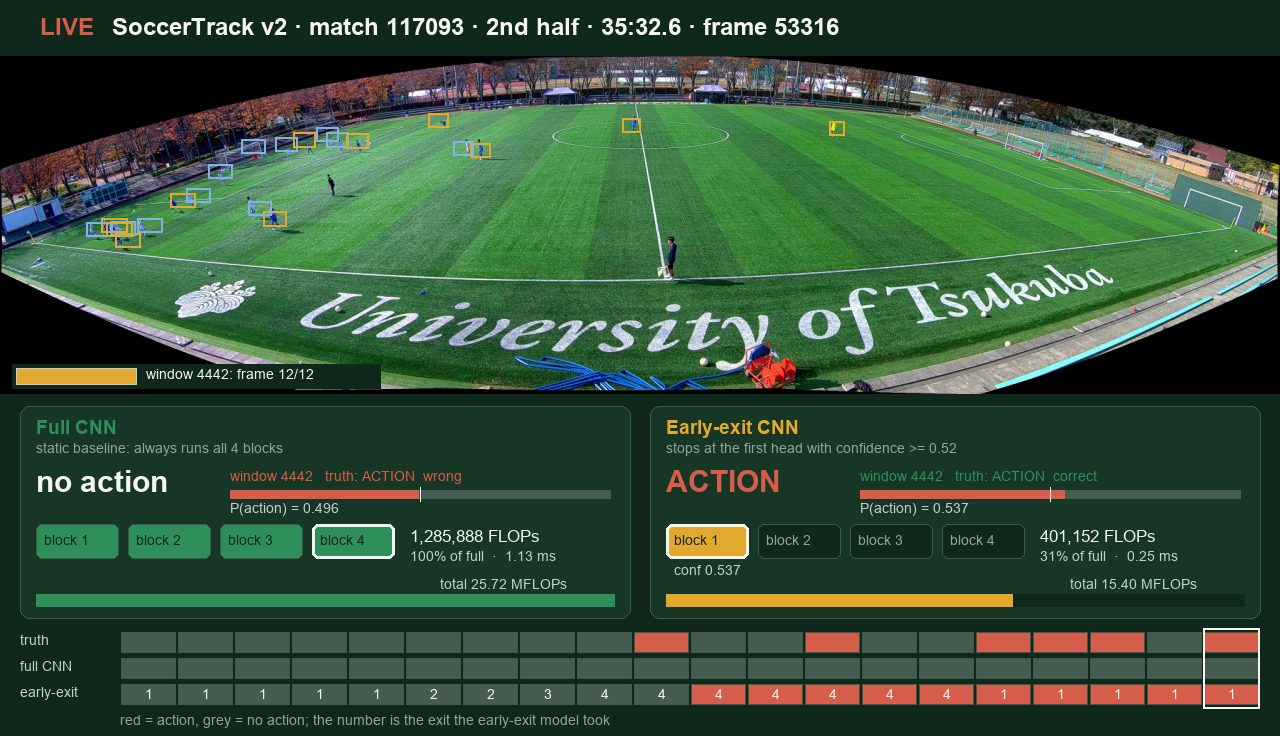

played 9.6 s of footage in 9.6 s wall-clock (1 frames not drawn to keep real time)
compute: early-exit 15.40 MFLOPs vs full CNN 25.72 MFLOPs (60%)   correct: full 14/20, early-exit 14/20


,truth,full CNN,early-exit,exit taken,early-exit FLOPs,full ms,early-exit ms
window,,,,,,,
4423,0,0,0,1,401152,1.101,0.289
4424,0,0,0,1,401152,2.039,0.268
4425,0,0,0,1,401152,1.178,0.237
4426,0,0,0,1,401152,1.947,0.281
4427,0,0,0,1,401152,1.873,0.259
4428,0,0,0,2,696320,1.149,0.393
4429,0,0,0,2,696320,1.389,0.348
4430,0,0,0,3,991488,1.381,0.441
4431,0,0,0,4,1286656,1.517,0.921


In [9]:
play_live()

## 5. A stretch of play: both models on consecutive windows

The same windows through both models. Top: ground truth and each model's call. Middle: which exit the early-exit model took.
Bottom: cumulative compute. The gap between the two lines is what early exiting saves.

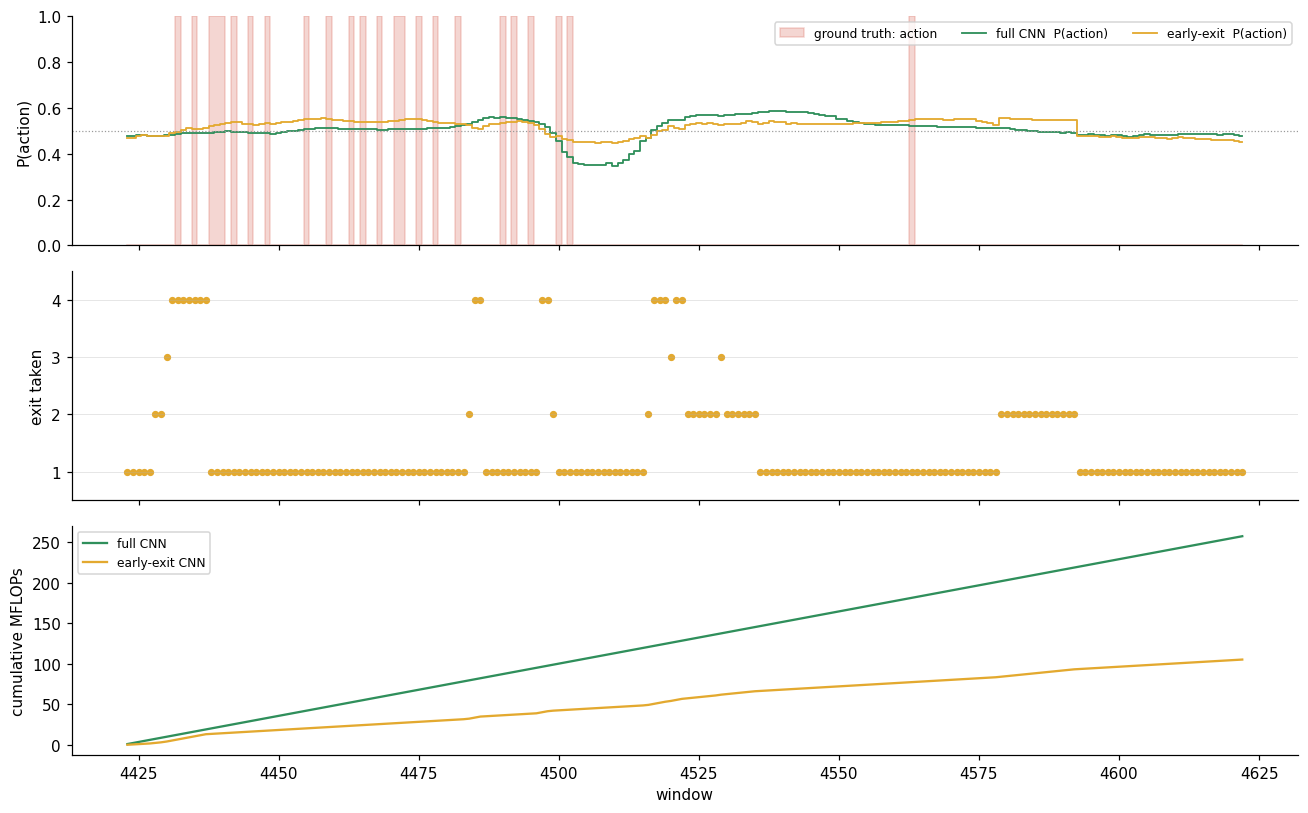

exit histogram (early-exit): {1: 150, 2: 31, 3: 3, 4: 16}   agreement between models: 85.0%


,full CNN,early-exit CNN
mean FLOPs / window,"1,285,888","526,598"
of full model,100%,41.0%
accuracy on these windows,0.450,0.390
mean latency (ms),0.350,0.235


In [10]:
START, NWIN = 4423, 200
trace = pd.DataFrame([run_both(i) for i in range(START, START + NWIN)]).set_index("window")
trace["t_s"] = [int(START_FRAME[i]) / FPS for i in trace.index]

fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
ax = axes[0]
ax.fill_between(trace.index, 0, trace["label"], step="mid", color=C_ACT, alpha=0.25, label="ground truth: action")
ax.step(trace.index, trace["full_p_action"], where="mid", color=C_FULL, lw=1.2, label="full CNN  P(action)")
ax.step(trace.index, trace["ee_p_action"],   where="mid", color=C_EE,   lw=1.2, label="early-exit  P(action)")
ax.axhline(0.5, color="#999", lw=0.8, ls=":"); ax.set_ylim(0, 1); ax.set_ylabel("P(action)"); ax.legend(loc="upper right", ncol=3, fontsize=8)

ax = axes[1]
ax.scatter(trace.index, trace["ee_exit"], s=14, color=C_EE)
ax.set_yticks([1, 2, 3, 4]); ax.set_ylabel("exit taken"); ax.set_ylim(0.5, 4.5); ax.grid(axis="y", lw=0.4, alpha=0.5)

ax = axes[2]
ax.plot(trace.index, trace["full_flops"].cumsum() / 1e6, color=C_FULL, label="full CNN")
ax.plot(trace.index, trace["ee_flops"].cumsum() / 1e6,   color=C_EE,   label="early-exit CNN")
ax.set_ylabel("cumulative MFLOPs"); ax.set_xlabel("window"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "full CNN":       [f"{trace['full_flops'].mean():,.0f}", "100%", f"{(trace['full_pred'] == trace['label']).mean():.3f}", f"{trace['full_ms'].mean():.3f}"],
    "early-exit CNN": [f"{trace['ee_flops'].mean():,.0f}", f"{100 * trace['ee_flops'].mean() / FLOPS_FULL:.1f}%", f"{(trace['ee_pred'] == trace['label']).mean():.3f}", f"{trace['ee_ms'].mean():.3f}"],
}, index=["mean FLOPs / window", "of full model", "accuracy on these windows", "mean latency (ms)"])
print(f"exit histogram (early-exit): {trace['ee_exit'].value_counts().sort_index().to_dict()}   agreement between models: {(trace['full_pred'] == trace['ee_pred']).mean():.1%}")
summary

## 6. The accuracy / compute knob: move the threshold

Run every exit once over the whole half, then re-apply the policy offline for any threshold. A higher threshold sends more
windows deeper into the trunk; a lower one answers at exit 1. The dashed line is the full CNN's balanced accuracy, the dotted
one the pruned CNN's.

In [11]:
@torch.no_grad()
def all_exit_logits(model, bs=512):
    outs = [stack_exit_logits(model(X[i:i+bs], MASK[i:i+bs])) for i in range(0, N, bs)]
    return torch.cat(outs, dim=1)                                      # [E, N, C]

LOGITS_EE   = all_exit_logits(ee)
LOGITS_FULL = all_exit_logits(full)[-1]
LOGITS_PRUN = all_exit_logits(pruned)[-1]
BAL_FULL = compute_metrics(LOGITS_FULL, Y)["bal_acc"]
BAL_PRUN = compute_metrics(LOGITS_PRUN, Y)["bal_acc"]
per_exit = pd.DataFrame([compute_metrics(LOGITS_EE[e], Y) | {"FLOPs": FLOPS_EXIT[e]} for e in range(ee.num_exits)],
                        index=[f"exit {e + 1}" for e in range(ee.num_exits)])
print(f"full CNN bal_acc {BAL_FULL:.3f} | pruned CNN bal_acc {BAL_PRUN:.3f} | early-exit per exit (no policy, every window answered at that exit):")
per_exit.round(3)

full CNN bal_acc 0.549 | pruned CNN bal_acc 0.542 | early-exit per exit (no policy, every window answered at that exit):


,acc,bal_acc,f1,FLOPs
exit 1,0.417,0.559,0.336,401152
exit 2,0.363,0.539,0.326,696320
exit 3,0.351,0.537,0.325,991488
exit 4,0.349,0.541,0.328,1286656


In [12]:
def policy_at(thr):
    thresholds = [thr, thr, thr, 0.0]
    preds, exit_ids, _ = apply_threshold_policy(LOGITS_EE, thresholds)
    chosen = LOGITS_EE[exit_ids, torch.arange(N)]
    m = compute_metrics(chosen, Y)
    return {"threshold": thr, "mean_flops": mean_flops(exit_ids, FLOPS_EXIT), "bal_acc": m["bal_acc"], "f1": m["f1"],
            "hist": exit_histogram(exit_ids, ee.num_exits)}

sweep = pd.DataFrame([policy_at(t) for t in np.round(np.arange(0.50, 0.701, 0.005), 3)])

def show_threshold(THRESHOLD=0.52):
    r = policy_at(THRESHOLD)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    ax = axes[0]
    ax.plot(100 * sweep["mean_flops"] / FLOPS_FULL, sweep["bal_acc"], "-o", ms=3, color=C_EE, label="early-exit, policy sweep")
    ax.scatter([100 * r["mean_flops"] / FLOPS_FULL], [r["bal_acc"]], s=120, color=C_EE, edgecolor="k", zorder=5, label=f"threshold = {THRESHOLD}")
    ax.scatter([100], [BAL_FULL], s=80, color=C_FULL, marker="s", zorder=5, label="full CNN")
    ax.scatter([100 * flops_pruned["flops_per_exit"][0] / FLOPS_FULL], [BAL_PRUN], s=80, color=C_PRUNED, marker="^", zorder=5, label="pruned CNN")
    ax.set_xlabel("mean compute per window (% of full CNN)"); ax.set_ylabel("balanced accuracy (this half)"); ax.legend(fontsize=8)
    ax = axes[1]
    ax.bar([1, 2, 3, 4], r["hist"], color=C_EE)
    ax.set_xticks([1, 2, 3, 4], [f"exit {k}" for k in (1, 2, 3, 4)]); ax.set_ylabel("windows")
    ax.set_title(f"mean {r['mean_flops']:,.0f} FLOPs = {100 * r['mean_flops'] / FLOPS_FULL:.1f}% of full | bal_acc {r['bal_acc']:.3f}  f1 {r['f1']:.3f}", fontsize=10)
    plt.tight_layout(); plt.show()

try:
    from ipywidgets import interact, FloatSlider
    interact(show_threshold, THRESHOLD=FloatSlider(min=0.50, max=0.70, step=0.005, value=0.52, readout_format=".3f", continuous_update=False));
except ImportError:
    show_threshold(0.52)

interactive(children=(FloatSlider(value=0.52, continuous_update=False, description='THRESHOLD', max=0.7, min=0…

## 7. The controller: a battery draining over the half

An edge box starts at 100% and spends battery in proportion to FLOPs. Above 50% and above 20% it uses the thresholds tuned
for those budgets (`outputs/earlyexit/thresholds.json`). Below 20% no threshold set met the budget, so the controller falls
back to exit 1 for every window. The full CNN spends the same amount on every window and drains fastest.

In [13]:
def level_for(b):
    return "100" if b > 50 else ("50" if b > 20 else "20")

@torch.no_grad()
def simulate_battery(capacity_fraction=0.35, start=0, n=None):
    n = n or (N - start)
    capacity = capacity_fraction * n * FLOPS_FULL        # full model on this fraction of windows would empty the battery
    b_ee = b_full = 100.0
    rows = []
    for i in range(start, start + n):
        lvl = level_for(b_ee)
        r = stream_window(ee, X[i:i+1], MASK[i:i+1], thr_by_budget[lvl])
        b_ee = max(0.0, b_ee - 100 * FLOPS_EXIT[r["exit"]] / capacity)
        b_full = max(0.0, b_full - 100 * FLOPS_FULL / capacity)
        rows.append({"window": i, "level": lvl, "exit": r["exit"] + 1, "battery_ee": b_ee, "battery_full": b_full,
                     "pred": r["pred"], "label": int(Y[i]), "flops": FLOPS_EXIT[r["exit"]]})
        if b_ee <= 0:
            break
    return pd.DataFrame(rows).set_index("window")

def show_battery(CAPACITY_FRACTION=0.35):
    sim = simulate_battery(CAPACITY_FRACTION)
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax = axes[0]
    ax.plot(sim.index, sim["battery_full"], color=C_FULL, label="full CNN")
    ax.plot(sim.index, sim["battery_ee"],   color=C_EE,   label="early-exit + controller")
    for lvl, col in (("100", "#2f8f5b"), ("50", "#e3a92f"), ("20", "#d65c4c")):
        seg = sim[sim["level"] == lvl]
        if len(seg):
            ax.axvspan(seg.index[0], seg.index[-1], color=col, alpha=0.08)
            ax.text(seg.index[0] + 15, 6, f"level {lvl}%: thresholds {thr_by_budget[lvl][:3]}", fontsize=8, color=col)
    ax.axhline(50, ls=":", color="#999", lw=0.8); ax.axhline(20, ls=":", color="#999", lw=0.8)
    full_dead = (sim["battery_full"] <= 0).idxmax() if (sim["battery_full"] <= 0).any() else None
    if full_dead is not None:
        ax.axvline(full_dead, color=C_FULL, ls="--", lw=0.8); ax.text(full_dead + 10, 60, "full CNN\nbattery empty", color=C_FULL, fontsize=8)
    ax.set_ylabel("battery (%)"); ax.set_ylim(0, 105); ax.legend(loc="upper right", fontsize=8)
    ax = axes[1]
    ax.scatter(sim.index, sim["exit"], s=4, color=C_EE, alpha=0.6); ax.set_yticks([1, 2, 3, 4]); ax.set_ylabel("exit taken"); ax.set_xlabel("window")
    plt.tight_layout(); plt.show()

    seg = sim.groupby("level", sort=False).agg(windows=("exit", "size"), mean_flops=("flops", "mean"),
                                               exit1=("exit", lambda s: int((s == 1).sum())), exit4=("exit", lambda s: int((s == 4).sum())),
                                               accuracy=("pred", lambda s: float((s == sim.loc[s.index, "label"]).mean())))
    seg["of full"] = (100 * seg["mean_flops"] / FLOPS_FULL).round(1).astype(str) + "%"
    print(f"windows survived: early-exit {len(sim):,} / {N:,}   full CNN {full_dead if full_dead is not None else len(sim):,}")
    return seg.round(3)

try:
    from ipywidgets import interact, FloatSlider
    interact(show_battery, CAPACITY_FRACTION=FloatSlider(min=0.2, max=1.0, step=0.05, value=0.35, continuous_update=False));
except ImportError:
    show_battery(0.35)

interactive(children=(FloatSlider(value=0.35, continuous_update=False, description='CAPACITY_FRACTION', max=1.…

## 8. The same windows on the real camera footage

`scripts/fetch_demo_frames.py` downloaded the SoccerTrack panorama frames for windows 4423-4442 (frames 53077-53316) with the
tracked boxes. Pick a window and see the model outputs next to the footage.

In [14]:
import cv2

CLIP = REPO / "data/raw/frames/117093_2nd_53077_240.mp4"
BOXES = json.loads((CLIP.with_name(CLIP.stem + "_boxes.json")).read_text()) if CLIP.exists() else {}
CLIP_FIRST, CLIP_N = 53077, 240
VIDEO_WINDOWS = [i for i in range(N) if CLIP_FIRST <= int(START_FRAME[i]) < CLIP_FIRST + CLIP_N - T + 1]

def camera_frame(frame_no):
    cap = cv2.VideoCapture(str(CLIP)); cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no - CLIP_FIRST)
    ok, img = cap.read(); cap.release()
    if not ok:
        return None
    s = img.shape[1] / 4096                                        # boxes are in native panorama pixels (4096 x 1080)
    for b in BOXES.get(str(frame_no), []):
        col = (47, 169, 227) if b["team"] == "right" else ((230, 179, 127) if b["team"] == "left" else (240, 240, 240))   # BGR: amber / blue / white
        cv2.rectangle(img, (int(b["x"] * s), int(b["y"] * s)), (int((b["x"] + b["w"]) * s), int((b["y"] + b["h"]) * s)), col, 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show_with_video(i):
    r = run_both(i)
    frame = camera_frame(int(START_FRAME[i]) + T // 2)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
    if frame is not None:
        axes[0].imshow(frame)
    axes[0].axis("off")
    t = int(START_FRAME[i]) / FPS
    axes[0].set_title(f"window {i}  t = {t // 60:.0f}:{t % 60:04.1f}   truth: {'ACTION' if r['label'] else 'no action'}   (boxes: amber = right team, blue = left, white = referee)", fontsize=10)
    plot_window(i, axes[1], title=False)
    lab = lambda c: "ACTION" if c == 1 else "no action"
    txt = (f"full CNN:        {lab(r['full_pred']):<10} P={r['full_p_action']:.3f}  {r['full_flops']:>9,} FLOPs\n"
           f"early-exit CNN:  {lab(r['ee_pred']):<10} P={r['ee_p_action']:.3f}  {r['ee_flops']:>9,} FLOPs  (exit {r['ee_exit']}, {100 * r['ee_flops'] / FLOPS_FULL:.0f}%)")
    fig.subplots_adjust(wspace=0.05, bottom=0.2, top=0.92)
    fig.text(0.13, 0.12, txt, family="monospace", fontsize=10, va="top"); plt.show()

if CLIP.exists():
    try:
        from ipywidgets import interact, SelectionSlider
        interact(show_with_video, i=SelectionSlider(options=VIDEO_WINDOWS, value=VIDEO_WINDOWS[0], description="window", continuous_update=False));
    except ImportError:
        show_with_video(VIDEO_WINDOWS[0])
else:
    print("no footage: run  python scripts/fetch_demo_frames.py  first")

interactive(children=(SelectionSlider(continuous_update=False, description='window', options=(4423, 4424, 4425…

In [15]:
# The pre-rendered 10 s clips (scripts/render_demo_clips.py): early-exit model on the left, full CNN on the right.
from IPython.display import Video, HTML, display
for name in ("clip_earlyexit.mp4", "clip_fullcnn.mp4"):
    p = REPO / "outputs/demo" / name
    if p.exists():
        display(HTML(f"<b>{name}</b>")); display(Video(str(p), embed=True, width=640))
    else:
        print(f"{name} not rendered yet")

## 9. Where this lands on the full test set

The numbers from the final evaluation (`outputs/final/results.csv`, M7: 22,841 test windows, two held-out matches).
All three models sit at about 0.55 balanced accuracy. The adaptive policy spends roughly a third of the full CNN's compute,
but the structurally pruned CNN gets there with even fewer FLOPs and a fifth of the parameters, which is why it is the only
Pareto-optimal point.

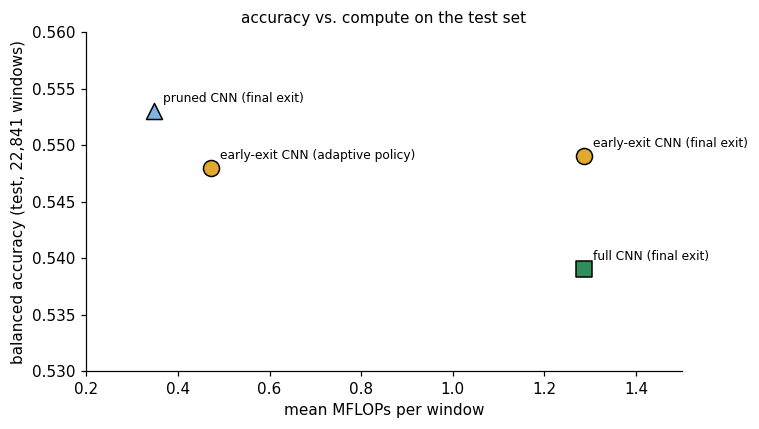

,flops_mean,% of full,bal_acc,f1,size_mb
model,,,,,
full CNN (final exit),1285888.000,100.0,0.539,0.310,0.230
pruned CNN (final exit),348032.000,27.1,0.553,0.336,0.071
early-exit CNN (final exit),1286656.000,100.1,0.549,0.330,0.234
early-exit CNN (adaptive policy),472046.079,36.7,0.548,0.326,0.234


In [16]:
res = pd.read_csv(REPO / "outputs/final/results.csv")
res = res[res["variant"].isin(["fp32", "fp32+pruned", "fp32/final_exit", "fp32/adaptive"]) & res["budget"].isin(["static", "100"])].copy()
res["model"] = res["model"].map({"cnn_full": "full CNN", "cnn_pruned": "pruned CNN", "earlyexit": "early-exit CNN"}) + np.where(res["variant"] == "fp32/adaptive", " (adaptive policy)", " (final exit)")
res["% of full"] = (100 * res["flops_mean"] / FLOPS_FULL).round(1)
res = res[["model", "flops_mean", "% of full", "bal_acc", "f1", "size_mb"]].round(3).set_index("model")

fig, ax = plt.subplots(figsize=(7, 4))
cols = {"full CNN (final exit)": C_FULL, "pruned CNN (final exit)": C_PRUNED, "early-exit CNN (final exit)": C_EE, "early-exit CNN (adaptive policy)": C_EE}
for name, row in res.iterrows():
    ax.scatter(row["flops_mean"] / 1e6, row["bal_acc"], s=110, color=cols[name], edgecolor="k", zorder=3, marker="s" if "full" in name else ("^" if "pruned" in name else "o"))
    ax.annotate(name, (row["flops_mean"] / 1e6, row["bal_acc"]), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel("mean MFLOPs per window"); ax.set_ylabel("balanced accuracy (test, 22,841 windows)"); ax.set_ylim(0.53, 0.56); ax.set_xlim(0.2, 1.5)
ax.set_title("accuracy vs. compute on the test set", fontsize=10)
plt.tight_layout(); plt.show()
res